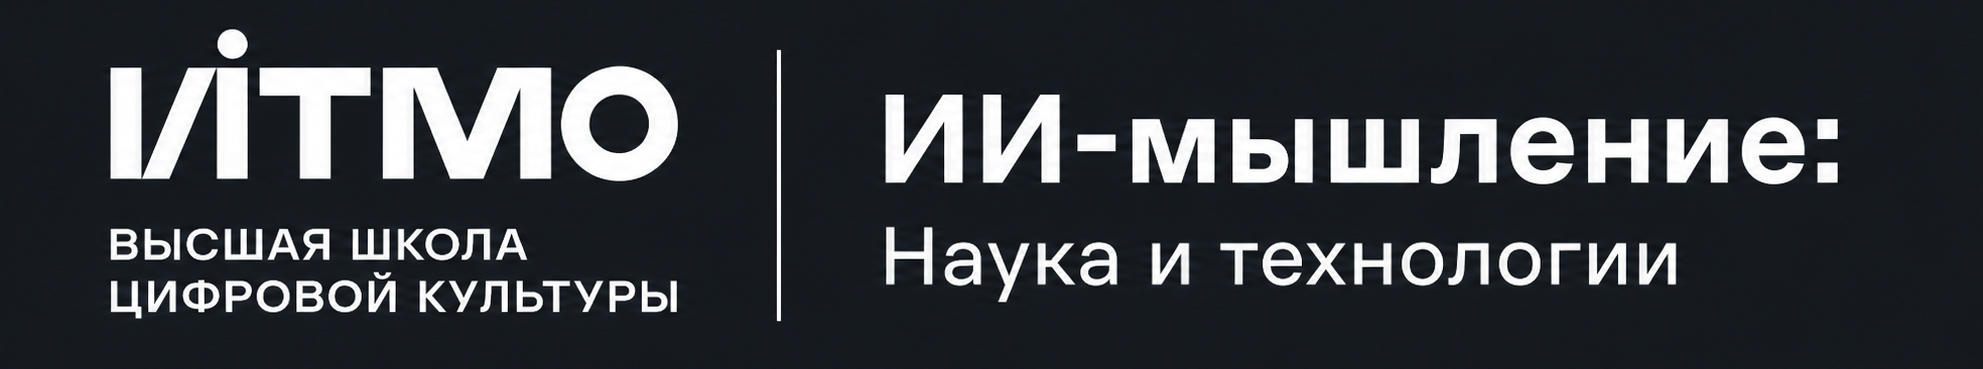

# Неделя 03. Архитектура Transformer и инференс (Общий трек)


## Информация
---
> **ФИО:** Самойло Александр Александрович
> 
> **ИСУ:** 563081

---


**Цель работы:** Исследовать компоненты архитектуры Transformer с точки зрения теории динамических систем, ОДУ и ренормализационной группы. Реализовать альтернативные схемы Residual Connections (Midpoint, Runge-Kutta 4) и оценить их устойчивость. Проанализировать энергетический ландшафт Residual Stream и эволюцию дисперсии скрытых состояний. Сравнить LayerNorm, RMSNorm и DyT (Dynamic Tanh Normalization). Реализовать SwiGLU, провести SVD-анализ весов FFN, рассчитать масштабирование памяти KV-Cache и MHA/GQA/MQA.


## Импорты

In [1]:
# ruff: noqa: F401, E402, I001, F811, E722
import os
import sys
import warnings

sys.modules['torchvision'] = None

os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
warnings.filterwarnings("ignore", category=UserWarning, module="huggingface_hub")
warnings.filterwarnings("ignore", category=UserWarning, module="transformers")
try:
    from huggingface_hub.utils import logging
    logging.set_verbosity_error()
except ImportError:
    pass

import subprocess


def print_ok(msg="Все проверки пройдены"):
    print(f"\033[92m[OK]\033[0m {msg}")


def print_error(msg=""):
    print(f"\033[91m[ERROR]\033[0m {msg}")


# Проверка и установка пакетов
required_packages = {
    'numpy': 'numpy',
    'torch': 'torch',
    'matplotlib': 'matplotlib',
    'transformers': 'transformers',
    'scipy': 'scipy'
}
for package, pip_name in required_packages.items():
    try:
        __import__(package)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

import numpy as np
import torch

print("Проверка версий библиотек:")
print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}")
print(f"PyTorch: {torch.__version__}")
try:
    import transformers
    print(f"Transformers: {transformers.__version__}")
except ImportError:
    pass

if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("\nНайдено устройство Apple Silicon (MPS). Вычисления будут выполняться на GPU Mac.")
elif torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"\nНайдено устройство CUDA: {torch.cuda.get_device_name(0)}. Вычисления будут выполняться на GPU.")
else:
    device = torch.device("cpu")
    print("\nВычислительные GPU не найдены. Вычисления будут выполняться на CPU.")

DEVICE = device
print(f"Активное устройство для PyTorch: {device}")

c:\Users\user1\projects\auth_text_processing\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Проверка версий библиотек:
Python: 3.14.3
NumPy: 2.4.2
PyTorch: 2.10.0+cpu
Transformers: 5.17.0

Вычислительные GPU не найдены. Вычисления будут выполняться на CPU.
Активное устройство для PyTorch: cpu


In [2]:
import math

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from transformers import AutoModelForCausalLM, AutoTokenizer

# Задание 1. Градиентный поток и стабильность в глубоких сетях (Vanishing Gradients & ReZero)

Остаточные связи (Residual Connections) вида `x_next = x + F(x)` являются критически важным элементом 
глубоких нейросетей, предотвращающим затухание градиентов. Интересно, что при некорректной инициализации 
или при очень большой глубине остаточные связи могут приводить к нестабильности (взрыву дисперсии).

Для решения этой проблемы была предложена схема **ReZero** (`x_next = x + alpha * F(x)`), где `alpha` — обучаемый 
параметр, инициализированный нулем. Это позволяет безопасно обучать глубокие сети без сложных схем warmup и нормализаций.

В этом задании мы:
1. Реализуем три вида блоков: Plain (обычный), Residual (остаточный) и ReZero.
2. Проанализируем затухание градиентов при обратном проходе на глубине 20 слоев.
3. Сравним скорость сходимости на простой задаче обучения.


In [3]:
class PlainBlock(nn.Module):
    def __init__(self, d_model: int):
        super().__init__()
        self.linear = nn.Linear(d_model, d_model)
        self.act = nn.ReLU()
        nn.init.normal_(self.linear.weight, mean=0.0, std=0.2)
        nn.init.zeros_(self.linear.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.act(self.linear(x)) #прямой проход без residual связи


class ResidualBlock(nn.Module):
    def __init__(self, d_model: int):
        super().__init__()
        self.linear = nn.Linear(d_model, d_model)
        self.act = nn.ReLU()
        nn.init.normal_(self.linear.weight, mean=0.0, std=0.2)
        nn.init.zeros_(self.linear.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x+self.act(self.linear(x)) #cлой с классической остаточной связью (residual connection)


class ReZeroBlock(nn.Module):
    def __init__(self, d_model: int):
        super().__init__()
        self.linear = nn.Linear(d_model, d_model)
        self.act = nn.ReLU()
        nn.init.normal_(self.linear.weight, mean=0.0, std=0.2)
        nn.init.zeros_(self.linear.bias)
        self.alpha = nn.Parameter(torch.tensor(0.0)) # при инициализации равен 0

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x+self.alpha*self.act(self.linear(x)) #по схеме ReZero, сигнал на старте не искажается из-за инициализации a=0

In [4]:
try:
    torch.manual_seed(42)
    x_test = torch.randn(2, 4, 16)
    plain_test = PlainBlock(16)
    res_test = ResidualBlock(16)
    rezero_test = ReZeroBlock(16)

    assert plain_test(x_test).shape == x_test.shape, "Неправильный shape у PlainBlock"
    assert res_test(x_test).shape == x_test.shape, "Неправильный shape у ResidualBlock"
    assert rezero_test(x_test).shape == x_test.shape, "Неправильный shape у ReZeroBlock"

    # Проверка инициализации ReZero
    assert torch.allclose(rezero_test(x_test), x_test), "У ReZeroBlock при инициализации alpha=0 выход должен быть равен входу!"

    # Проверка обучаемости alpha
    opt_test = optim.SGD(rezero_test.parameters(), lr=0.1)
    loss_test = rezero_test(x_test).sum()
    loss_test.backward()
    opt_test.step()
    assert rezero_test.alpha.item() != 0.0, "Параметр alpha в ReZeroBlock должен обучаться!"

    print("[OK] Базовые тесты для блоков Задания 1 пройдены!")
except Exception:
    print("[ERROR] Тестирование блоков завершилось ошибкой:")
    import traceback
    traceback.print_exc()

[OK] Базовые тесты для блоков Задания 1 пройдены!


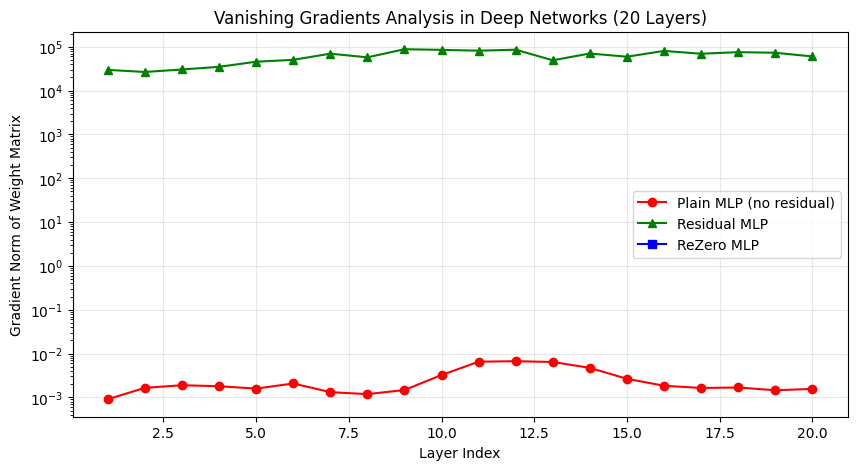

Отношение градиента последнего слоя к первому в Plain: 1.72e+00
Отношение градиента последнего слоя к первому в Residual: 2.03
[OK] Тест схем глубоких сетей пройден


In [5]:
# Анализ градиентного затухания в глубоких сетях
import matplotlib.pyplot as plt


def get_gradient_norms(model_class, num_layers=20, d_model=16):
    torch.manual_seed(42)
    blocks = nn.ModuleList([model_class(d_model) for _ in range(num_layers)])
    x = torch.randn(4, 8, d_model)
    curr = x
    for block in blocks:
        curr = block(curr)
    loss = curr.sum()
    loss.backward()
    
    grad_norms = []
    for block in blocks:
        grad = block.linear.weight.grad
        if grad is not None:
            grad_norms.append(grad.norm().item())
        else:
            grad_norms.append(0.0)
    return grad_norms


plain_grads = get_gradient_norms(PlainBlock)
res_grads = get_gradient_norms(ResidualBlock)
rezero_grads = get_gradient_norms(ReZeroBlock)

plt.figure(figsize=(10, 5))
plt.plot(range(1, 21), plain_grads, 'r-o', label='Plain MLP (no residual)')
plt.plot(range(1, 21), res_grads, 'g-^', label='Residual MLP')
plt.plot(range(1, 21), rezero_grads, 'b-s', label='ReZero MLP')
plt.yscale('log')
plt.xlabel('Layer Index')
plt.ylabel('Gradient Norm of Weight Matrix')
plt.title('Vanishing Gradients Analysis in Deep Networks (20 Layers)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print(f"Отношение градиента последнего слоя к первому в Plain: {plain_grads[-1]/max(plain_grads[0], 1e-15):.2e}")
print(f"Отношение градиента последнего слоя к первому в Residual: {res_grads[-1]/res_grads[0]:.2f}")
print("[OK] Тест схем глубоких сетей пройден")

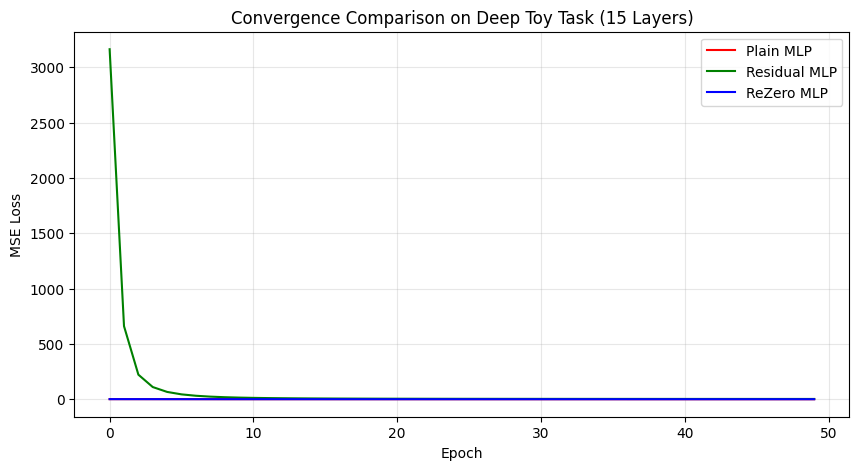

In [6]:
# Обучение на синтетической задаче регрессии
torch.manual_seed(42)
num_samples = 100
X = torch.randn(num_samples, 16)
Y = torch.sin(X[:, 0:1]) + torch.cos(X[:, 1:2])


def train_toy_network(model_class, epochs=50):
    torch.manual_seed(42)
    blocks = nn.ModuleList([model_class(16) for _ in range(15)])
    optimizer = optim.Adam(blocks.parameters(), lr=0.01)
    criterion = nn.MSELoss()
    losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        curr = X
        for block in blocks:
            curr = block(curr)
        output = curr.mean(dim=-1, keepdim=True)
        loss = criterion(output, Y)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses


plain_losses = train_toy_network(PlainBlock)
res_losses = train_toy_network(ResidualBlock)
rezero_losses = train_toy_network(ReZeroBlock)

plt.figure(figsize=(10, 5))
plt.plot(plain_losses, 'r', label='Plain MLP')
plt.plot(res_losses, 'g', label='Residual MLP')
plt.plot(rezero_losses, 'b', label='ReZero MLP')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Convergence Comparison on Deep Toy Task (15 Layers)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

> ***Вопрос на подумать***
>
> 1. Каким образом добавление residual связей решает проблему затухания градиентов (vanishing gradients) при обратном проходе? Напишите формулу протекания градиента.
> 2. Почему в схеме ReZero инициализация $\alpha = 0$ обеспечивает стабильность при начале обучения, даже если сеть состоит из сотен слоев?
>
> ***Ответ:*** 1. В сети без остаточных связей выход представляет собой компоицию функций Xl+1=Fl(Xl), градиент функции потерь вычисляется по цепному правилу через длинное матричное произведение якобианов. Если нормы якобинов ∥∂Fl/∂xl∥<1, градиент затухает экспоненциально по глубине. Добавлнеие остаточной связи превращает производную шага в сумму, где при раскрытии скобок образуется сумма слагаемых содержащая единичную матрицу ∂L/∂x1 = ∂L/∂xL(I+∑…). Единичная матрица создаёт магистральный канал без умножений на веса, гарантируя прохождение градиента к начальным слоям, даже при ∥∂Fl/∂xl∥ стремямщимся к нулю. На построенном графике затухания градентов видно что  в Residual MLP норма градиента держится на уровне ∼5⋅10^4, тогда как в Plain MLP она падает до 10^−3, градиент затухает. В ReZero градиент весов на старте равен строго 0, так как α=0.

> 2. При α=0 вклад нелинейного блока полностью обнуляется, на нулевом шаге вся глубокая сеть вырождается в тождественный оператор, где выход сети строго равен входу: xL = x0. Полностью исключается взрыв и затухание дисперсий активаций на прямом проходе. Градиент потерь на первом шаге проходит без затухания через единичный оператор. Сеть сама, шаг за шагом, начинает дозированно пропускать сигнал через сложные слои, избавляя от необходимости подбирать сложный warmup скорости обучения и нормализационные слои. На графике сходимости видно, что обычный Residual без нормализации на старте взрывает ошибку, Plain MLP застревает на на ошибке ∼1.0 из-за нулевых градиентов. ReZero за счёт α=0 стартует с минимальной ошибки и сходится быстрее и стабильнее всех.



# Задание 2. Нормы скрытых состояний (Residual Stream) и сохранение признаков

Residual connection `x_next = x + F(x)` позволяет сохранять масштаб признаков при прохождении через слои. Без остаточных связей (`x_next = F(x)`) масштаб вектора скрытого состояния может экспоненциально затухать, что делает сеть неспособной передавать информацию на глубокие уровни.

В этом задании мы проанализируем изменение норм векторов скрытых состояний по слоям SmolLM2 и сравним это с поведением сети без остаточных связей.

**Реализуйте:**
- Класс `ToyTransformerBlock` с отключаемой остаточной связью.
- Сравнение эволюции норм векторов признаков в сетях с residual connections и без них.


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 272/272 [00:00<00:00, 316.87it/s]


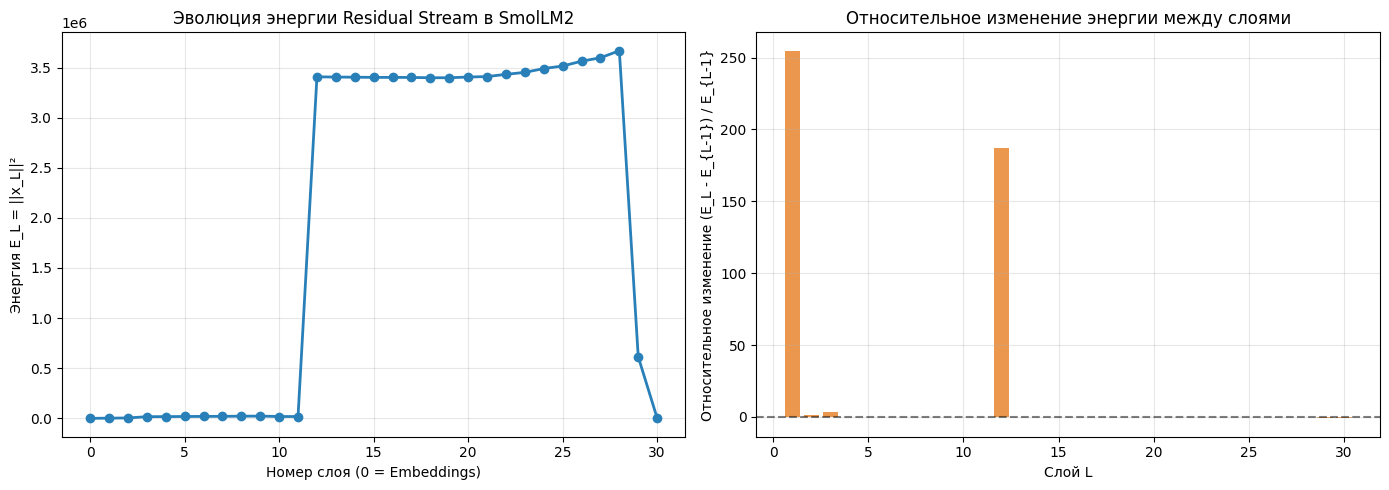

Начальная энергия (Embeddings): 7.09
Финальная энергия (Слой 30): 2471.26
Отношение финальной энергии к начальной: 348.50


In [3]:
model_name = "HuggingFaceTB/SmolLM2-135M"
tokenizer = AutoTokenizer.from_pretrained(model_name, token=False)
tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    token=False,
    device_map="auto" if torch.cuda.is_available() else None,
    torch_dtype=torch.float32
)
model.eval()
config = model.config

physics_text = (
    "Newton's second law: F = ma. "
    "For a mass m = 2 kg on a frictionless incline at 30°, "
    "the acceleration is a = g sin(theta) = 9.8 x 0.5 = 4.9 m/s^2. "
    "The force along the incline is F = 2 x 4.9 = 9.8 N. "
    "After t = 3 seconds, velocity v = v₀ + at = 0 + 4.9 x 3 = 14.7 m/s."
)

# Анализ эволюции энергии residual stream по слоям SmolLM2
# токенизация физического текста и прямой проход с сохранением скрытых состояний
inputs = tokenizer(physics_text, return_tensors="pt").to(DEVICE)

with torch.no_grad():
    outputs = model(**inputs, output_hidden_states=True)

# outputs.hidden_states содержит эмбеддинги + выходы всех 30 слоев модели
hidden_states = outputs.hidden_states

# вычисление средней энергии E_L = ||x_L||^2 по всем токенам для каждого слоя
energies_smollm = []
for h in hidden_states:
    # (batch, seq_len, d_model) -> норма в квадрате по признакам, усредненная по токенам
    e_l = (h ** 2).sum(dim=-1).mean().item()
    energies_smollm.append(e_l)

# относительное изменение энергии между соседними слоями: (E_L - E_{L-1}) / E_{L-1}
rel_changes = [
    (energies_smollm[i] - energies_smollm[i - 1]) / energies_smollm[i - 1]
    for i in range(1, len(energies_smollm))
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

layers = list(range(len(energies_smollm)))
ax1.plot(layers, energies_smollm, "o-", color="#2980b9", linewidth=2)
ax1.set_xlabel("Номер слоя (0 = Embeddings)")
ax1.set_ylabel("Энергия E_L = ||x_L||²")
ax1.set_title("Эволюция энергии Residual Stream в SmolLM2")
ax1.grid(True, alpha=0.3)

ax2.bar(range(1, len(energies_smollm)), rel_changes, color="#e67e22", alpha=0.8)
ax2.axhline(0, color="black", linestyle="--", alpha=0.5)
ax2.set_xlabel("Слой L")
ax2.set_ylabel("Относительное изменение (E_L - E_{L-1}) / E_{L-1}")
ax2.set_title("Относительное изменение энергии между слоями")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Начальная энергия (Embeddings): {energies_smollm[0]:.2f}")
print(f"Финальная энергия (Слой {len(energies_smollm)-1}): {energies_smollm[-1]:.2f}")
print(f"Отношение финальной энергии к начальной: {energies_smollm[-1] / energies_smollm[0]:.2f}")

In [8]:
from ast import List
from typing import Tuple


class ToyTransformerBlock(nn.Module):
    def __init__(self, d_model: int, use_residual: bool = True, eps: float = 1e-5):
        super().__init__()
        self.d_model = d_model
        self.use_residual = use_residual
        
        # подслой трансформации F(x)
        self.linear = nn.Linear(d_model, d_model)
        self.act = nn.ReLU()
        nn.init.normal_(self.linear.weight, mean=0.0, std=0.2)
        nn.init.zeros_(self.linear.bias)

    def forward(self, x: torch.Tensor, F=None, dt: float = 1.0) -> torch.Tensor:
        # если передан внешний оператор F, использование его, иначе собственный линейный слой
        fx = self.act(self.linear(x)) if F is None else F(x)
        if self.use_residual:
            return x + dt * fx
        return fx

class ToyTransformer(nn.Module):
    def __init__(self, d_model: int, num_layers: int, use_residual: bool = True):
        super().__init__()
        self.blocks = nn.ModuleList([
            ToyTransformerBlock(d_model, use_residual=use_residual)
            for _ in range(num_layers)
        ])

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, List[float]]:
        energies = []
        # сохранение энергии входного сигнала E_0
        energies.append((x ** 2).sum(dim=-1).mean().item())
        
        curr = x
        for block in self.blocks:
            curr = block(curr)
            # энергия состояния после каждого слоя
            energies.append((curr ** 2).sum(dim=-1).mean().item())
            
        return curr, energies

In [10]:
try:
    tb_res = ToyTransformerBlock(64, use_residual=True)
    tb_no_res = ToyTransformerBlock(64, use_residual=False)
    x_t = torch.randn(2, 4, 64)
    out_res = tb_res(x_t)
    out_no_res = tb_no_res(x_t)
    assert out_res.shape == x_t.shape, "Неправильный размер выхода ToyTransformerBlock"
    
    t_res = ToyTransformer(64, 5, use_residual=True)
    _, E_res = t_res(x_t)
    assert len(E_res) == 6, "Неправильное количество слоев энергии"
    print_ok("Тест ToyTransformerBlock и ToyTransformer пройден")
except Exception as e:
    print_error(f"Тест ToyTransformer Block провален: {e}")

[OK] Тест ToyTransformerBlock и ToyTransformer пройден


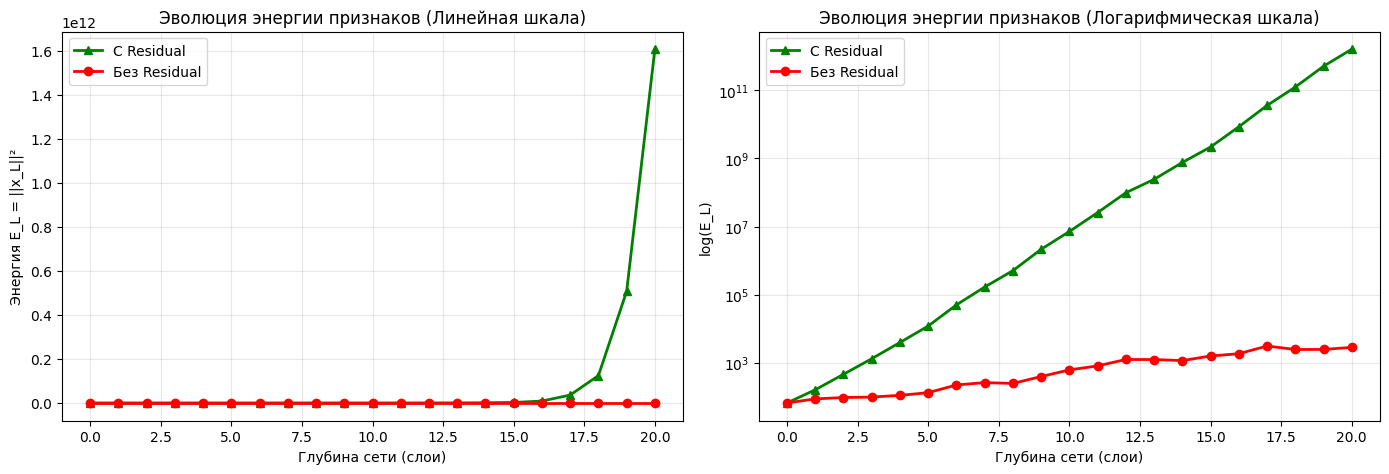

Без Residual: Начальная = 6.64e+01, Финальная = 2.85e+03
С Residual:   Начальная = 6.64e+01, Финальная = 1.61e+12


In [11]:
# Сравнение эволюции нормы скрытых состояний с residual connections и без них
torch.manual_seed(42)
d_model_toy = 64
num_layers_toy = 20

# две модели с остаточными связями и без них
toy_res = ToyTransformer(d_model_toy, num_layers_toy, use_residual=True)
toy_no_res = ToyTransformer(d_model_toy, num_layers_toy, use_residual=False)

x_sample = torch.randn(4, 8, d_model_toy)

_, energies_with_res = toy_res(x_sample)
_, energies_without_res = toy_no_res(x_sample)

# графики в линейной и логарифмической шкалах
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
layer_indices = list(range(num_layers_toy + 1))

# линейная шкала
ax1.plot(layer_indices, energies_with_res, "g-^", label="С Residual", linewidth=2)
ax1.plot(layer_indices, energies_without_res, "r-o", label="Без Residual", linewidth=2)
ax1.set_xlabel("Глубина сети (слои)")
ax1.set_ylabel("Энергия E_L = ||x_L||²")
ax1.set_title("Эволюция энергии признаков (Линейная шкала)")
ax1.legend()
ax1.grid(True, alpha=0.3)

# логарифмическая шкала
ax2.plot(layer_indices, energies_with_res, "g-^", label="С Residual", linewidth=2)
ax2.plot(layer_indices, energies_without_res, "r-o", label="Без Residual", linewidth=2)
ax2.set_yscale("log")
ax2.set_xlabel("Глубина сети (слои)")
ax2.set_ylabel("log(E_L)")
ax2.set_title("Эволюция энергии признаков (Логарифмическая шкала)")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Без Residual: Начальная = {energies_without_res[0]:.2e}, Финальная = {energies_without_res[-1]:.2e}")
print(f"С Residual:   Начальная = {energies_with_res[0]:.2e}, Финальная = {energies_with_res[-1]:.2e}")

> ***Вопрос на подумать***
>
> С точки зрения теоремы Нётер («каждой непрерывной симметрии соответствует закон сохранения»), какую именно симметрию привносит в скрытое пространство residual connection, обеспечивающий сохранение энергии (информации)?
>
> ***Ответ:*** Остаточная связь (xl+1=xl+F(xl)) привносит в сеть трансляционную симметрию вдоль глубины (симметрию сдвига по координате слоя / непрерывному времени t в аналогии с ОДУ). В обычной сети без остаточных связей каждый слой заново поворачивает, сжимает и деформирует координатную сетку признаков, нарушена транслционная симметрия и сигнал и его норма затухают. В архитектуре с Residual Connections формируется единая общая информационная магистраль Residual Stream, пространство признаков сохраняет единый глобальный базис от слоя к слою, слои не переписывают скрытое состояние, а лишь вносят малые аддитивные поправки. Инвариантность относительно сдвига по слоям порождает закон сохранения информации. Информация входного токена не затухает экспоненциально, а беспрепятственно транслируется через всю глубину до финального классификатора.

> В модели SmolLM2-135M энергия скрытого состояния не исчезает: начав с E0=7.09 на эмбеддингах, она сохраняется на протяжении всех 30 слоев и на выходе составляет E30=2471.26(отношение 348.50).ToyTransformer без остаточных связей передача информации ограничена, тогда как с остаточными связями энергия беспрепятственно накапливается через аддитивный поток от 6.64×10^1 до 1.61×10^12.

# Задание 3. Роль LayerNorm / RMSNorm в стабилизации распределения признаков

Поскольку residual соединения накапливают информацию (аддитивный поток), дисперсия и масштаб скрытых векторов склонны расти с глубиной. Чтобы стабилизировать распределение и удерживать активации в рабочих областях функций активации, применяется нормализация (LayerNorm или RMSNorm).

В этом задании мы исследуем эволюцию математического ожидания и дисперсии скрытых векторов SmolLM2 и реализуем слой LayerNorm с нуля.

**Реализуйте:**
- Мониторинг среднего значения и дисперсии скрытых состояний SmolLM2 по слоям.
- Класс `LayerNorm` с нуля.
- Проверку поведения глубокой сети без нормализации.


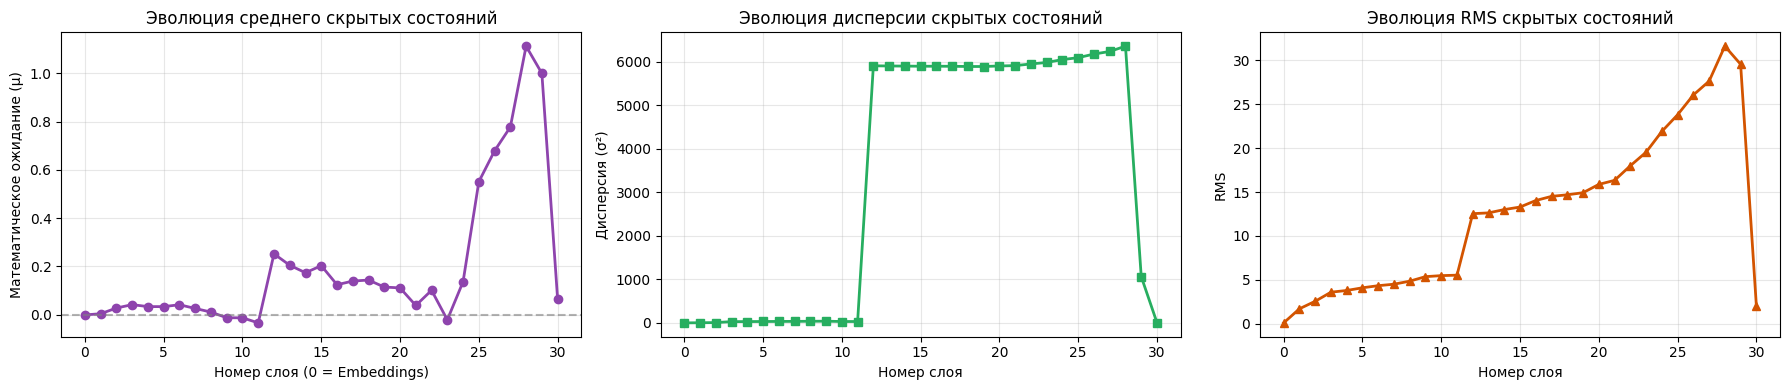

Слой 0 (Embeddings): Mean = -0.0010, Var = 0.0123, RMS = 0.1100
Слой 30 (Финал):     Mean = 0.0651, Var = 4.2825, RMS = 2.0685


In [4]:
# Анализ эволюции среднего значения и дисперсии скрытых состояний по слоям SmolLM2

means_smollm = []
vars_smollm = []
rms_smollm = []
# hidden_states от модели SmolLM2
for h in hidden_states:
    # h имеет форму (batch_size, seq_len, d_model)
    # среднее по размерности признаков (dim=-1), усредненное по всем токенам
    m = h.mean(dim=-1).mean().item()
    # дисперсия по размерности признаков (dim=-1)
    v = h.var(dim=-1, unbiased=False).mean().item()
    # RMS = sqrt(mean(x^2))
    r = torch.sqrt((h ** 2).mean(dim=-1)).mean().item()
    
    means_smollm.append(m)
    vars_smollm.append(v)
    rms_smollm.append(r)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4))
layers_idx = list(range(len(hidden_states)))

ax1.plot(layers_idx, means_smollm, "o-", color="#8e44ad", linewidth=2)
ax1.axhline(0, color="gray", linestyle="--", alpha=0.6)
ax1.set_xlabel("Номер слоя (0 = Embeddings)")
ax1.set_ylabel("Математическое ожидание (μ)")
ax1.set_title("Эволюция среднего скрытых состояний")
ax1.grid(True, alpha=0.3)

ax2.plot(layers_idx, vars_smollm, "s-", color="#27ae60", linewidth=2)
ax2.set_xlabel("Номер слоя")
ax2.set_ylabel("Дисперсия (σ²)")
ax2.set_title("Эволюция дисперсии скрытых состояний")
ax2.grid(True, alpha=0.3)

ax3.plot(layers_idx, rms_smollm, "^-", color="#d35400", linewidth=2)
ax3.set_xlabel("Номер слоя")
ax3.set_ylabel("RMS")
ax3.set_title("Эволюция RMS скрытых состояний")
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Слой 0 (Embeddings): Mean = {means_smollm[0]:.4f}, Var = {vars_smollm[0]:.4f}, RMS = {rms_smollm[0]:.4f}")
print(f"Слой 30 (Финал):     Mean = {means_smollm[-1]:.4f}, Var = {vars_smollm[-1]:.4f}, RMS = {rms_smollm[-1]:.4f}")

In [5]:
class LayerNorm(nn.Module):
    def __init__(self,dim: int, eps: float = 1e-5):
        super().__init__()
        self.eps = eps
        # обучаемые параметры масштабирования и смещения
        self.weight = nn.Parameter(torch.ones(dim))
        self.bias = nn.Parameter(torch.zeros(dim))

    def forward(self, x):
        # среднее и дисперсия по последней размерности (dim=-1)
        mean = x.mean(dim=-1, keepdim=True)
        # дисперсия: 1/d * sum((x - mean)^2)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        
        # нормализация и аффинное преобразование
        x_norm = (x - mean) / torch.sqrt(var + self.eps)
        return x_norm * self.weight + self.bias

class RMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float = 1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # RMS = sqrt(1/d * sum(x^2))
        rms = torch.sqrt(torch.mean(x ** 2, dim=-1, keepdim=True) + self.eps)
        return (x / rms) * self.weight

In [6]:
try:
    ln = LayerNorm(64)
    rms_n = RMSNorm(64)
    x_t = torch.randn(2, 4, 64) * 2.0
    out_ln = ln(x_t)
    out_rms = rms_n(x_t)
    assert torch.allclose(out_ln.var(dim=-1, unbiased=False).mean(), torch.tensor(1.0), atol=1e-2), "Дисперсия LayerNorm не равна 1"
    assert torch.allclose((out_rms ** 2).mean(dim=-1).mean(), torch.tensor(1.0), atol=1e-2), "RMS RMSNorm не равен 1"
    print_ok("Тест LayerNorm и RMSNorm пройден")
except Exception as e:
    print_error(f"Тест LayerNorm/RMSNorm провален: {e}")

[OK] Тест LayerNorm и RMSNorm пройден


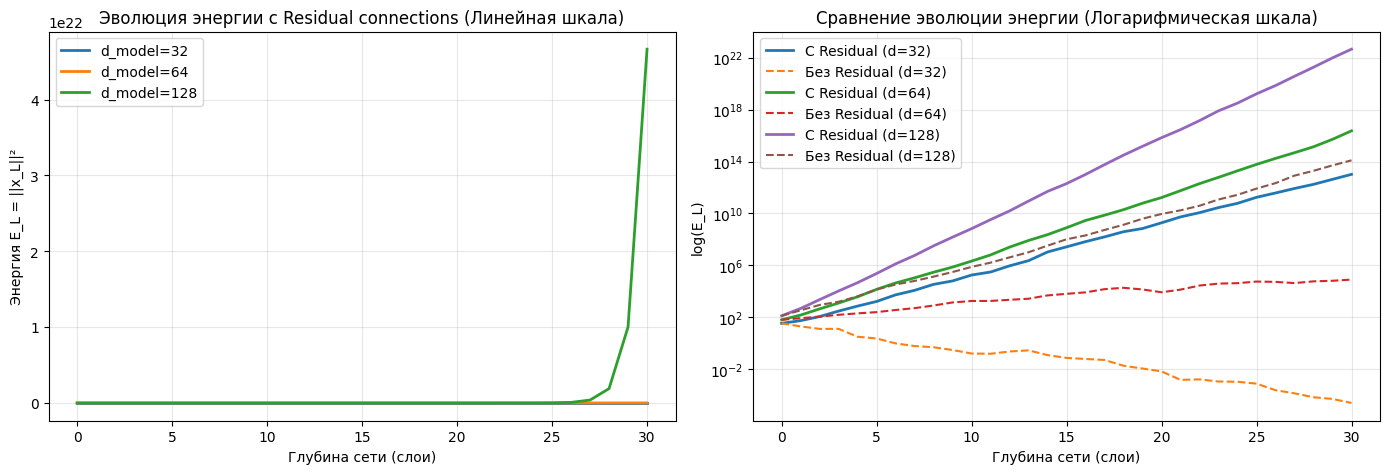

Замеры энергий на слое 30 для разных d_model (с Residual):
d_model =  32: E_0 = 3.34e+01 -> E_30 = 1.20e+12
d_model =  64: E_0 = 6.63e+01 -> E_30 = 5.25e+16
d_model = 128: E_0 = 1.30e+02 -> E_30 = 2.82e+22


In [9]:
# Анализ эволюции энергии в глубокой сети (30 слоев)
torch.manual_seed(42)
d_models = [32, 64, 128]
num_layers_deep = 30
layers_deep_idx = list(range(num_layers_deep + 1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for d in d_models:
    # сеть С Residual connections
    net_res = ToyTransformer(d, num_layers_deep, use_residual=True)
    # сеть БЕЗ Residual connections
    net_no_res = ToyTransformer(d, num_layers_deep, use_residual=False)
    
    x_input = torch.randn(4, 8, d)
    _, e_res = net_res(x_input)
    _, e_no_res = net_no_res(x_input)
    
    # линейный график для сетей с Residual
    ax1.plot(layers_deep_idx, e_res, label=f"d_model={d}", linewidth=2)
    # логарифмический график для сравнения обоих режимов
    ax2.plot(layers_deep_idx, e_res, label=f"С Residual (d={d})", linewidth=2)
    ax2.plot(layers_deep_idx, e_no_res, "--", label=f"Без Residual (d={d})", linewidth=1.5)

ax1.set_xlabel("Глубина сети (слои)")
ax1.set_ylabel("Энергия E_L = ||x_L||²")
ax1.set_title("Эволюция энергии с Residual connections (Линейная шкала)")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.set_yscale("log")
ax2.set_xlabel("Глубина сети (слои)")
ax2.set_ylabel("log(E_L)")
ax2.set_title("Сравнение эволюции энергии (Логарифмическая шкала)")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Замеры энергий на слое 30 для разных d_model (с Residual):")
for d in d_models:
    net_temp = ToyTransformer(d, num_layers_deep, use_residual=True)
    _, e_temp = net_temp(torch.randn(4, 8, d))
    print(f"d_model = {d:3d}: E_0 = {e_temp[0]:.2e} -> E_30 = {e_temp[-1]:.2e}")

> ***Вопрос на подумать***
>
> Каким образом LayerNorm/RMSNorm можно соотнести с оператором ренормализационной группы (RG) в физике фазовых переходов? Какую роль играет фиксированная точка $\sigma^2 = 1$?
>
> ***Ответ:*** В физике фазовых переходов оператор ренормализационной группы R устраняет микроскопические высокочастотные флуктуации и осуществляет масштабное преобразование, приводя параметры системы к инвариантному критическому масштабу.  
> В трансформере аддитивный поток x_{l+1} = x_l + F(x_l) на каждом слое накапливает энергию. Слои LayerNorm / RMSNorm действуют в точности как дискретный оператор RG:  
> * устранение макроскопического дрейфа среднего (центрирование $\mu$ в LayerNorm);  
> * выполнение масштабного сжатия (деление на $\sigma$ или RMS), возвращая раздувшиеся степени свободы к фиксированному масштабу признаков.  

> Фиксированная точка $\sigma^2 = 1$ удерживает сеть в критическом состоянии:  
> * Если бы $\sigma^2$ стремилась в бесконечности (неустойчивая «горячая» фаза): логиты в Softmax взрываются, распределение схлопывается в $\text{argmax}$, градиенты обнуляются, обучение останавливается.  
> * Если бы $\sigma^2$ стремилась к нулю (неустойчивая «холодная» фаза): все логиты обнуляются, Softmax выдает равномерный шум 1/N, смысловая информация разрушается.  
> Фиксированная точка $\sigma^2 = 1$ удерживает скрытые векторы строго в квазилинейной динамической зоне активаций и Softmax, обеспечивая устойчивый градиентный поток через любую глубину.  
 
> * Без нормализации при просмотре графика во время анализа эволюции энергии в глубокой сети следует заметить, что система не имеет устойчивой точки RG. При d=128 энергия E_L экспоненциально взрывается до E30 = 2.82 * 10^22, а без residual при d=32 затухает до 10^{-4}.  
> * С нормализацией в SmolLM2 на графике несмотря на всплеск дисперсии в средних слоях на слоях 12–28 из-за сложения сотен признаков, финальный слой нормализации успешно проецирует систему обратно в окрестность фиксированной точки: на 30 слое Var = 4.28, RMS = 2.07 и Mean ~ 0.065, удерживая модель в стабильном состоянии.

# Задание 4. FFN как высокоразмерное проецирование признаков

Полносвязный блок (Feed-Forward Network, FFN) в трансформере обычно проецирует признаки из размерности `d_model` в промежуточную размерность `d_ff` (которая в 2.67-4 раза больше) с применением нелинейности, а затем возвращает обратно в `d_model`. Это расширение позволяет модели выражать сложные нелинейные комбинации признаков.

В этом задании мы изучим эффективный ранг матриц FFN в SmolLM2 с помощью сингулярного разложения (SVD) и напишем свой модуль `GELU_FFN`.

**Реализуйте:**
- Анализ эффективного ранга (ранга стабильности) проекционных матриц FFN модели SmolLM2.
- Класс `GELU_FFN` с нуля.
- Сравнение выходов вашей реализации со встроенным блоком SwiGLU.


In [10]:
# Задание 4. Анализ параметров SmolLM2
import pandas as pd

# извлечение гиперпараметров из конфигурации модели
d_model = config.hidden_size             # 576
num_heads = config.num_attention_heads   # 9
num_kv_heads = config.num_key_value_heads # 3 (используется GQA!)
d_ff = config.intermediate_size          # 1536
num_layers = config.num_hidden_layers    # 30
vocab_size = config.vocab_size           # 49152
head_dim = d_model // num_heads          # 64

# аналитический расчет параметров по компонентам
# Attention: W_q (d x d), W_k (d x d_kv), W_v (d x d_kv), W_o (d x d)
q_params = d_model * (num_heads * head_dim)
k_params = d_model * (num_kv_heads * head_dim)
v_params = d_model * (num_kv_heads * head_dim)
o_params = (num_heads * head_dim) * d_model
attn_per_layer = q_params + k_params + v_params + o_params
total_attn_params = num_layers * attn_per_layer

# FFN (SwiGLU имеет 3 матрицы: gate_proj, up_proj, down_proj)
ffn_per_layer = 3 * (d_model * d_ff)
total_ffn_params = num_layers * ffn_per_layer

# RMSNorm (по 2 нормализации на слой + финальная нормализация модели)
total_norm_params = (num_layers * 2 + 1) * d_model

# Embeddings (эмбеддинги токенов, веса связаны с LM Head: tie_word_embeddings=True)
total_embed_params = vocab_size * d_model

calculated_total = total_attn_params + total_ffn_params + total_norm_params + total_embed_params
actual_total = sum(p.numel() for p in model.parameters())

params_data = [
    {"Компонент": "Embeddings", "Параметры": total_embed_params, "Доля (%)": total_embed_params / actual_total * 100},
    {"Компонент": "Attention (Q, K, V, O)", "Параметры": total_attn_params, "Доля (%)": total_attn_params / actual_total * 100},
    {"Компонент": "FFN (Gate, Up, Down)", "Параметры": total_ffn_params, "Доля (%)": total_ffn_params / actual_total * 100},
    {"Компонент": "RMSNorm", "Параметры": total_norm_params, "Доля (%)": total_norm_params / actual_total * 100},
    {"Компонент": "Расчетный итог", "Параметры": calculated_total, "Доля (%)": calculated_total / actual_total * 100},
    {"Компонент": "Фактический итог", "Параметры": actual_total, "Доля (%)": 100.0}
]

df_params = pd.DataFrame(params_data)
display(df_params)

print(f"Разница между расчетом и фактом: {abs(calculated_total - actual_total)} параметров")

,Компонент,Параметры,Доля (%)
0,Embeddings,28311552,21.047133
1,"Attention (Q, K, V, O)",26542080,19.731687
2,"FFN (Gate, Up, Down)",79626240,59.195060
3,RMSNorm,35136,0.026121
4,Расчетный итог,134515008,100.000000
5,Фактический итог,134515008,100.000000


Разница между расчетом и фактом: 0 параметров


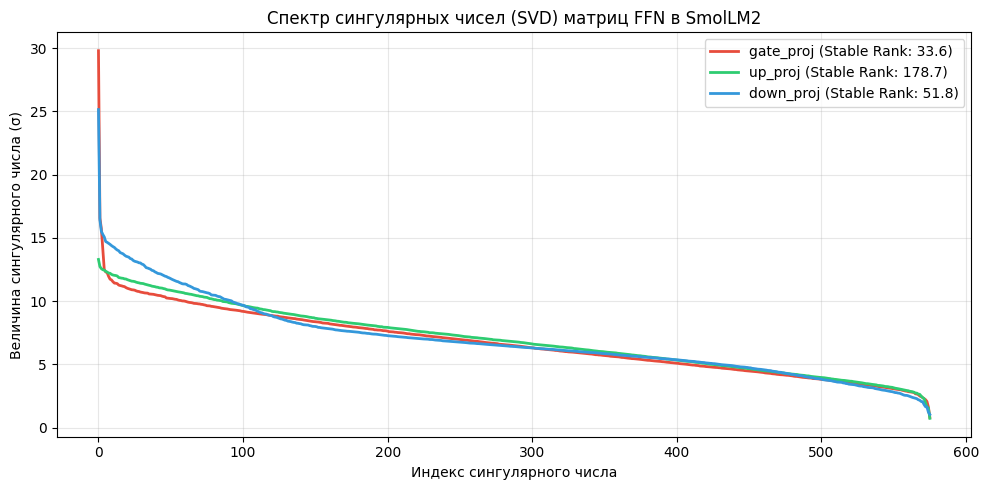

Максимально возможный ранг: 576
Эффективный ранг gate_proj: 33.55
Эффективный ранг up_proj:   178.67
Эффективный ранг down_proj: 51.80


In [11]:
# извлечение матрицы FFN первого слоя модели
layer0_mlp = model.model.layers[0].mlp
w_gate = layer0_mlp.gate_proj.weight.data.float()  # (1536, 576)
w_up = layer0_mlp.up_proj.weight.data.float()      # (1536, 576)
w_down = layer0_mlp.down_proj.weight.data.float()  # (576, 1536)

# вычисление сингулярных чисел через SVD
_, s_gate, _ = torch.linalg.svd(w_gate, full_matrices=False)
_, s_up, _ = torch.linalg.svd(w_up, full_matrices=False)
_, s_down, _ = torch.linalg.svd(w_down, full_matrices=False)

# расчета эффективного ранга (Stable Rank = ||W||_F^2 / ||W||_2^2 = sum(s^2) / s_max^2)
def stable_rank(s):
    return (s ** 2).sum() / (s[0] ** 2)

rank_gate = stable_rank(s_gate).item()
rank_up = stable_rank(s_up).item()
rank_down = stable_rank(s_down).item()

# Визуализация спектров сингулярных чисел
plt.figure(figsize=(10, 5))
plt.plot(s_gate.cpu().numpy(), label=f"gate_proj (Stable Rank: {rank_gate:.1f})", color="#e74c3c", linewidth=2)
plt.plot(s_up.cpu().numpy(), label=f"up_proj (Stable Rank: {rank_up:.1f})", color="#2ecc71", linewidth=2)
plt.plot(s_down.cpu().numpy(), label=f"down_proj (Stable Rank: {rank_down:.1f})", color="#3498db", linewidth=2)
plt.xlabel("Индекс сингулярного числа")
plt.ylabel("Величина сингулярного числа (σ)")
plt.title("Спектр сингулярных чисел (SVD) матриц FFN в SmolLM2")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Максимально возможный ранг: {min(d_model, d_ff)}")
print(f"Эффективный ранг gate_proj: {rank_gate:.2f}")
print(f"Эффективный ранг up_proj:   {rank_up:.2f}")
print(f"Эффективный ранг down_proj: {rank_down:.2f}")

In [12]:
class GELU_FFN(nn.Module):
    """Стандартный FFN с GELU (как в GPT-2)"""

    def __init__(self, d_model, d_ff):
        super().__init__()
        self.w1 = nn.Linear(d_model, d_ff)
        self.act = nn.GELU()
        self.w2 = nn.Linear(d_ff, d_model)

    def forward(self, x):
        # проекция d_model -> d_ff, нелинейность GELU, обратная проекция d_ff -> d_model
        return self.w2(self.act(self.w1(x)))

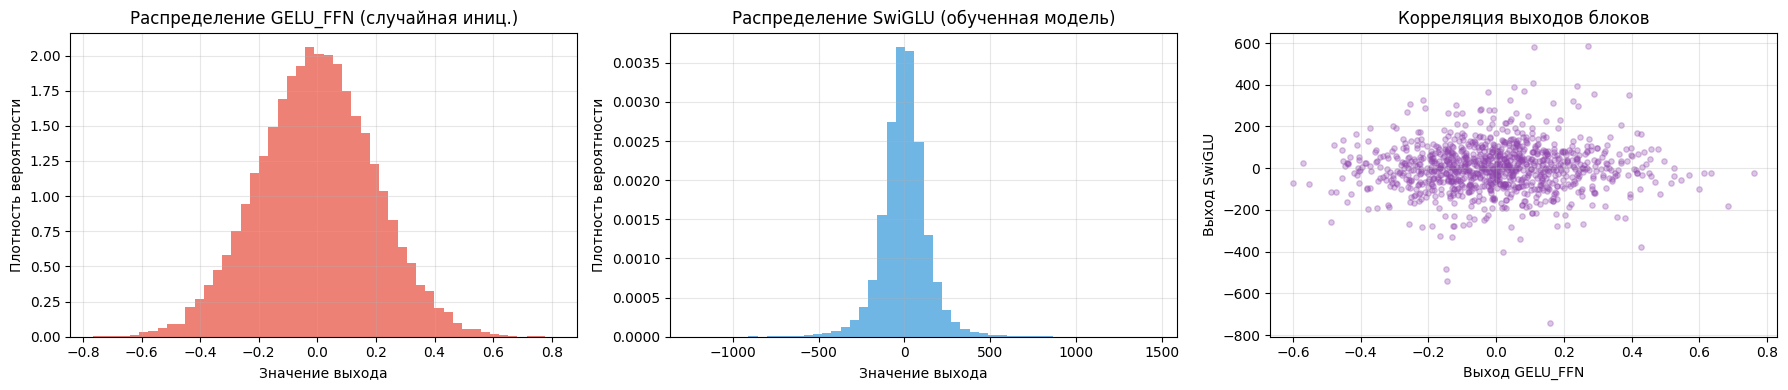

Диапазон выходов GELU_FFN:   min = -0.7656, max = 0.8090
Диапазон выходов SwiGLU FFN: min = -1231.5137, max = 1456.0858
Коэффициент корреляции выходов: 0.0123


In [15]:
# инициализация и сравнение выходов GELU_FFN и встроенного SwiGLU блоком модели
torch.manual_seed(42)

# инициализация блока GELU_FFN с эквивалентным бюджетом параметров
d_ff_gelu = int(3 * d_ff / 2)  # 2304
gelu_ffn = GELU_FFN(d_model=d_model, d_ff=d_ff_gelu)

# получение встроенного блока SwiGLU из первого слоя модели
swiglu_ffn = model.model.layers[0].mlp

# прогон случайного тензора через оба блока
x_test_mlp = torch.randn(4, 16, d_model)
with torch.no_grad():
    out_gelu = gelu_ffn(x_test_mlp)
    out_swiglu = swiglu_ffn(x_test_mlp)

out_gelu_flat = out_gelu.flatten().cpu().numpy()
out_swiglu_flat = out_swiglu.flatten().cpu().numpy()

# графики распределений выходов и корреляции
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4))

# 1. Распределение выходов GELU_FFN
ax1.hist(out_gelu_flat, bins=50, color="#e74c3c", alpha=0.7, density=True)
ax1.set_xlabel("Значение выхода")
ax1.set_ylabel("Плотность вероятности")
ax1.set_title("Распределение GELU_FFN (случайная иниц.)")
ax1.grid(True, alpha=0.3)

# 2. Распределение выходов SwiGLU (SmolLM2)
ax2.hist(out_swiglu_flat, bins=50, color="#3498db", alpha=0.7, density=True)
ax2.set_xlabel("Значение выхода")
ax2.set_ylabel("Плотность вероятности")
ax2.set_title("Распределение SwiGLU (обученная модель)")
ax2.grid(True, alpha=0.3)

# 3. Диаграмма рассеяния
ax3.scatter(out_gelu_flat[:1000], out_swiglu_flat[:1000], alpha=0.3, color="#8e44ad", s=15)
ax3.set_xlabel("Выход GELU_FFN")
ax3.set_ylabel("Выход SwiGLU")
ax3.set_title("Корреляция выходов блоков")
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

corr = np.corrcoef(out_gelu_flat, out_swiglu_flat)[0, 1]
print(f"Диапазон выходов GELU_FFN:   min = {out_gelu_flat.min():.4f}, max = {out_gelu_flat.max():.4f}")
print(f"Диапазон выходов SwiGLU FFN: min = {out_swiglu_flat.min():.4f}, max = {out_swiglu_flat.max():.4f}")
print(f"Коэффициент корреляции выходов: {corr:.4f}")

> ***Вопрос на подумать***
>
> Почему с точки зрения «фазового пространства» расширение размерности $d_{model} \rightarrow d_{ff} \rightarrow d_{model}$ является принципиальным для эффективной аппроксимации функций в Transformer?
>
> ***Ответ:*** В исходном низкоразмерном фазовом пространстве (dmodel=576) нелинейные семантические многообразия сильно запутаны. Согласно теореме Ковера, нелинейное отображение входного вектора в фазовое пространство существенно более высокой размерности (dff=1536, расширение в ≈2.67 раза) с высокой вероятностью делает сложные нелинейные комбинации признаков **линейно разделимыми**, позволяя функции активации изолировать нужные паттерны.

> Блок FFN действует как память «ключ–значение». Расширение скрытого слоя позволяет разместить большое количество ортогональных нейронов-детекторов. В таблице параметров на FFN приходится самая большая доля весов модели - 59.20%, в то время как на внимание уходит лишь 19.73%. Именно расширение до dff даёт модели ёмкость для хранения фактов.

> Сингулярный анализ показал, что матрицы FFN имеют низкий стабильный ранг: у gate_proj эффективный ранг составляет всего 33.55 из 576 возможных, а у down_proj — 51.80. Внутреннее расширение до dff = 1536 создаёт необходимый запас размерности фазового пространства, гарантируя, что обратная проекция в dmodel не приведёт к потере значимых компонент сигнала. При сравнении выходов блоков видно, что за счет гейтового механизма обученный SwiGLU имеет значительно более широкий динамический диапазон выходов от -1231.5137 до 1456.1 против базового GELU -0.7656 до 0.81.



> ***Вопрос на подумать***
>
> 1. Как причинная маска влияет на распределение Softmax в строках внимания? Почему для маскирования используется значение $-\infty$?
> 2. В чем разница между маскированием в энкодере (BERT) и декодере (GPT)?
>
> ***Ответ:*** 

> 1. В авторегрессионных моделях распределение Softmax в каждой строке нормируется В авторегрессионных моделях распределение Softmax в каждой строке нормируется только по позициям прошлого и настоящего (j<=i). Причинная маска отсекает все будущие токены (j>i), гарантируя, что сумма вероятностей строго равна 1.0 на допустимом префиксе. Для маскирования используется значение  $-\infty$, чтобы математически предел от exp(x) был равен нулю. В результате числитель обнуляется, и веса внимания к будущим токенам становятся строго равны 0.0, исключая их влияние на взвешенную сумму Value-векторов. Если бы маскировали нулями, то будущие токены получали бы положительную вероятность и была бы утечка ответов.

> 2. В энкодере BERT маскирование происходит на уровне входных данных, где перед обучением случайные 15% токенов физически заменяются заглушкой [MASK]. Внутри самой нейросети ограничений нет, поэтому механизм внимания остается полностью двунаправленным — каждый токен свободно смотрит на весь контекст слева и справа. Такая схема нужна, чтобы модель глубоко понимала взаимосвязи в тексте, и применяется она исключительно на этапе обучения.

> В декодере GPT, напротив, входной текст остается нетронутым, а маскирование встраивается напрямую в механизм внимания с помощью нижнетреугольной матрицы. Этот математический фильтр зануляет веса для всех последующих слов, делая внимание строго однонаправленным. Маска в GPT используется всегда — и при обучении, и на инференсе, — гарантируя авторегрессионную генерацию, при которой модель предсказывает каждое новое слово слева направо и физически не может подглядеть в собственное будущее.


---
# Ссылки и полезные материалы

- [RMSNorm: Root Mean Square Layer Normalization (Zhang & Sennrich, 2019)](https://arxiv.org/abs/1910.07467)
- [SwiGLU: GLU Variants Improve Transformer (Shazeer, 2020)](https://arxiv.org/abs/2002.05202)
- [GQA: Training Generalized Multi-Query Attention from Multi-Head Checkpoints (Ainslie et al., 2023)](https://arxiv.org/abs/2305.13245)
- [DyT: Transformers without Normalization (Zhu et al., 2025)](https://arxiv.org/abs/2503.10622)
- [Euler method and ODEs in Deep Learning (Weinan E, 2017)](https://arxiv.org/abs/1707.03661)
- [Renormalization Group and Deep Learning (Mehta & Schwab, 2014)](https://arxiv.org/abs/1410.3831)
